# GPT-2 small activation atlas: exploring stage 1

Reads the outputs of `python -m atlas` (see `docs/atlas-design.md`) and looks at what they say about GPT-2 small.
Build them first with `run-atlas`: 1M tokens, one 127-token window from each of ~8k documents across two OpenWebText
files, run as 8 shards for bootstrap errors; about 5 minutes on an M4.

1. Residual-stream geometry: how variance and effective dimension grow with depth
2. MLP neurons: firing rates and peak activations by layer
3. Single units: a neuron's histogram and top contexts; a residual dimension's top and bottom contexts
4. Statistical errors (bootstrap over shards) and the corpus systematic (file vs file)
5. Regression check: stored exemplar pointers reproduce on recompute

Figures are saved to `docs/figures/` for `docs/results.md`; run headless with `run-notebook`.

All statistics exclude position 0 (BOS) and are conditional on OpenWebText and positions 1–127.

In [1]:
import json
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import torch
import pandas as pd
from atlas import HFGPT2, bootstrap_weights, pooled_moments

ATLAS = Path("../results/atlas")
FIGURES = Path("../docs/figures")  # figures for docs/results.md
manifest = json.loads((ATLAS / "manifest.json").read_text())
neurons = duckdb.sql(f"select * from '{ATLAS / 'neurons.parquet'}'").df()
topk = duckdb.sql(f"select * from '{ATLAS / 'topk.parquet'}'").df()
resid = np.load(ATLAS / "resid.npz")
hists = np.load(ATLAS / "histograms.npz")
tokens = np.load(ATLAS / "tokens.npy", mmap_mode="r")

# Categorical slots 1-4 and text inks of the dataviz default palette, as in the ioi-hydra notebook.
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e5e4df"
def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")

def tidy(ax):
    ax.grid(axis="y", color=GRID, zorder=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

print(f"{manifest['n_rows']:,} rows x {manifest['seq_len']} tokens from {manifest['n_docs']:,} documents "
      f"({manifest['dataset']} files {manifest['files']}, at most {manifest['max_windows_per_doc']} window per document)")
print(f"{neurons['n'].iloc[0]:,} tokens per unit; {len(neurons):,} units; {len(topk):,} top- and bottom-k exemplars")

7,814 rows x 128 tokens from 7,814 documents (Skylion007/openwebtext files [0, 1], at most 1 window per document)
992,378 tokens per unit; 46,848 units; 1,136,640 top- and bottom-k exemplars


## 1. Residual-stream geometry

From the per-layer covariance in `resid.npz` ("layer 12" is the final residual stream, the input to `ln_final`).

- **Total variance**, the trace of the covariance: how much the stream's spread grows with depth.
- **Effective dimension**, the participation ratio $(\sum_i \lambda_i)^2 / \sum_i \lambda_i^2$ of the eigenvalues: about
  1 if one direction carries everything, 768 if variance is spread evenly.
- **Largest single basis dimension's share of variance**: the residual basis is not privileged in general, but GPT-2 is
  known to have a few outlier dimensions (447 among them).

*Expect:* variance growing roughly exponentially with depth, and a low effective dimension where outlier dimensions dominate.

layer  total var        eff. dim      dims for 90%  top basis dim (share)
    0      11.6 ± 0.0     14.3 ± 0.0            410   479 (2%)
    1    1032.4 ± 0.7     31.1 ± 0.0            314   480 (8%)
    2    1321.3 ± 0.7     46.2 ± 0.0            327   480 (7%)
    3    1662.0 ± 1.0     71.7 ± 0.1            378   480 (5%)
    4    2155.3 ± 1.3    103.8 ± 0.2            424   480 (4%)
    5    2666.6 ± 1.5    131.3 ± 0.3            450   480 (3%)
    6    3378.0 ± 2.2    150.7 ± 0.3            468   480 (3%)
    7    4338.0 ± 3.3    164.8 ± 0.3            485   480 (2%)
    8    5857.8 ± 5.2    170.5 ± 0.3            500   447 (2%)
    9    8105.6 ± 6.4    171.9 ± 0.3            507   447 (2%)
   10   11936.7 ± 8.2    157.9 ± 0.4            515   481 (2%)
   11   19060.2 ± 15.7   103.9 ± 0.4            509   496 (2%)
   12   56020.4 ± 174.0    6.8 ± 0.0            347   496 (11%)


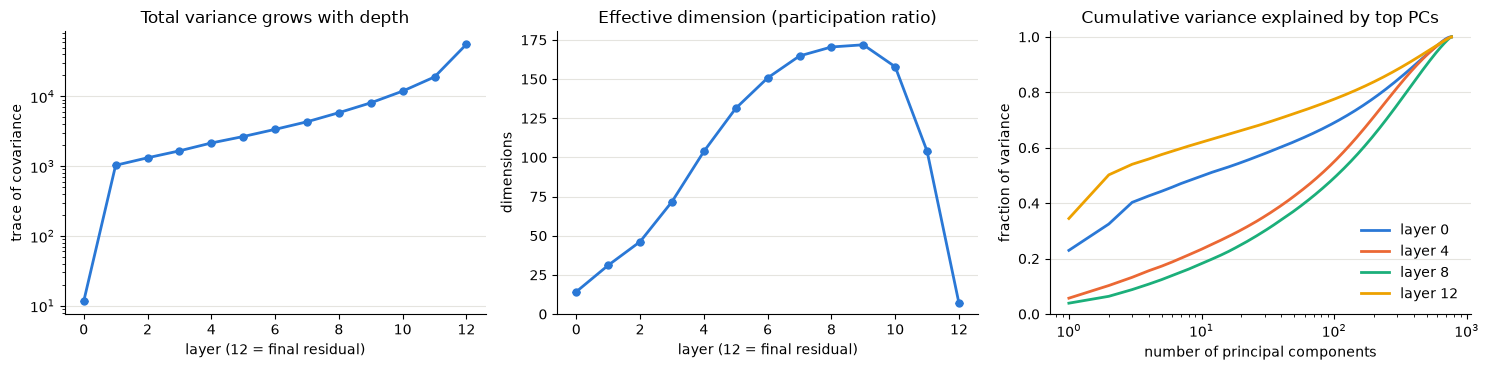

In [2]:
layers, cov = resid["layer"], resid["cov"]
eig = np.linalg.eigvalsh(cov)[:, ::-1]  # [13, 768], descending
total, pr = resid["total_var"], resid["pr"]  # = eig.sum(1) and eig.sum(1)**2 / (eig**2).sum(1)
total_err, pr_err = resid["total_var_err"], resid["pr_err"]  # bootstrap over shards
diag = np.diagonal(cov, axis1=1, axis2=2)
top_dim, top_share = diag.argmax(1), diag.max(1) / total
dims90 = (np.cumsum(eig, 1) / total[:, None] < 0.9).sum(1) + 1

print("layer  total var        eff. dim      dims for 90%  top basis dim (share)")
for l in layers:
    print(f"{l:5d}  {total[l]:8.1f} ± {total_err[l]:<5.1f}  {pr[l]:5.1f} ± {pr_err[l]:<4.1f}  {dims90[l]:12d}  {top_dim[l]:4d} ({top_share[l]:.0%})")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].errorbar(layers, total, yerr=total_err, fmt="o-", color=C[0], lw=2, ms=5, capsize=3)
axes[0].set(yscale="log", title="Total variance grows with depth", xlabel="layer (12 = final residual)", ylabel="trace of covariance")
axes[1].errorbar(layers, pr, yerr=pr_err, fmt="o-", color=C[0], lw=2, ms=5, capsize=3)
axes[1].set(title="Effective dimension (participation ratio)", xlabel="layer (12 = final residual)", ylabel="dimensions", ylim=(0, None))
for i, l in enumerate([0, 4, 8, 12]):
    axes[2].plot(np.arange(1, 769), np.cumsum(eig[l]) / total[l], color=C[i], lw=2, label=f"layer {l}")
axes[2].set(xscale="log", title="Cumulative variance explained by top PCs", xlabel="number of principal components", ylabel="fraction of variance", ylim=(0, 1.02))
axes[2].legend(frameon=False, loc="lower right")
for ax in axes:
    tidy(ax)
plt.tight_layout()
save(fig, "results_resid_geometry")

**Reading it.** The first block multiplies the stream's variance by about 90 (layer 0 is the embedding alone), and it
grows steadily after that, another 3× in the last block. The effective dimension rises from 14 to about 170 by layers
7–9, then collapses to about 7 at the final residual stream, where a handful of directions carry most of the variance
(the top principal component alone carries about a third). In the basis, dimension 480 stands out early (7.5% of the
variance at layer 1, falling to 2% by layer 7); from layer 7 to 11 no dimension carries more than about 2.5%, so which
one is largest there is not meaningful. At the final residual, dimensions 496, 430 and 36 carry 11%, 8% and 8%. The
bootstrap errors are tiny: the effective dimension is known to better than ±0.5 at every layer.

## 2. MLP neurons

Each neuron's firing rate (fraction of tokens with post-GELU activation > 0) and its peak activation, summarized per
layer as the median with a 10th–90th percentile band. Rarely-firing neurons are those with a firing rate below 1e-4,
fewer than about 100 tokens in 1M.

*Expect:* early layers to hold most of the rarely-firing neurons, and peak activations to grow in the last layers.

highest-peak neurons:
 layer  unit       max     mean      std  frac_pos      p999
    11  2378 58.221298 0.999975 5.352369  0.058201 47.806355
    10  2931 24.063875 0.277563 1.505810  0.064900 16.266401
    10  2114 21.109224 0.219241 1.783334  0.024583 17.121079
    11  3066 17.780052 0.366416 1.754594  0.097984 15.067857
    11  2679 17.729298 0.431497 1.785597  0.098891 14.409465


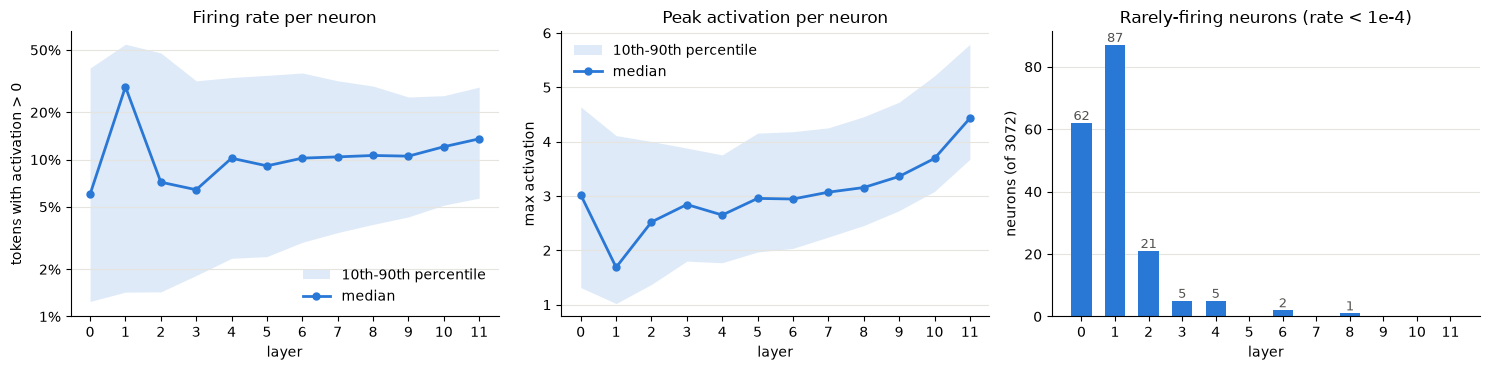

In [3]:
mlp = neurons[neurons.kind == "post"]
by = mlp.groupby("layer")
q = lambda col, p: by[col].quantile(p).to_numpy()
L = np.arange(12)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, title, ylabel, log in [
    (axes[0], "frac_pos", "Firing rate per neuron", "tokens with activation > 0", True),
    (axes[1], "max", "Peak activation per neuron", "max activation", False),
]:
    ax.fill_between(L, q(col, 0.1), q(col, 0.9), color=C[0], alpha=0.15, lw=0, label="10th-90th percentile")
    ax.plot(L, q(col, 0.5), "o-", color=C[0], lw=2, ms=5, label="median")
    ax.set(title=title, xlabel="layer", ylabel=ylabel, yscale="log" if log else "linear")
    if log:
        ax.set_yticks([0.01, 0.02, 0.05, 0.1, 0.2, 0.5], ["1%", "2%", "5%", "10%", "20%", "50%"])
        ax.yaxis.set_minor_locator(plt.matplotlib.ticker.NullLocator())
    ax.legend(frameon=False)
rare = by["frac_pos"].apply(lambda s: (s < 1e-4).sum()).to_numpy()
axes[2].bar(L, rare, color=C[0], width=0.6, zorder=2)
for l, n in zip(L, rare):
    if n:
        axes[2].text(l, n, str(n), ha="center", va="bottom", fontsize=9, color=INK2)
axes[2].set(title="Rarely-firing neurons (rate < 1e-4)", xlabel="layer", ylabel="neurons (of 3072)")
for ax in axes:
    ax.set_xticks(L)
    tidy(ax)
plt.tight_layout()
save(fig, "results_mlp_neurons")

print("highest-peak neurons:")
print(mlp.nlargest(5, "max")[["layer", "unit", "max", "mean", "std", "frac_pos", "p999"]].to_string(index=False))

**Reading it.** Layers 0–2 hold most of the rarely-firing neurons (62, 87 and 21 of 3072). Layer 1 is the odd one out:
its median neuron fires on about 30% of tokens, more than twice the median of any other layer. Peak activations climb steadily
through the last layers, and the highest-peak neurons are all in layers 10–11.

## 3. Single units

`show_neuron(layer, unit)` prints the neuron's summary row, plots its activation histogram (from `histograms.npz`, on
an asinh axis: linear near 0, logarithmic in the tails) and lists its top-activating contexts with the token marked «like this». For a residual dimension
(`hook="blocks.L.hook_resid_pre"`), which is signed, it also lists the bottom (most negative) contexts.

blocks.9.mlp.hook_post unit 1000: mean -0.082, std 0.145, max 3.76, fires on 7.8% of tokens, p50 -0.116, p99 0.61, p99.9 1.36


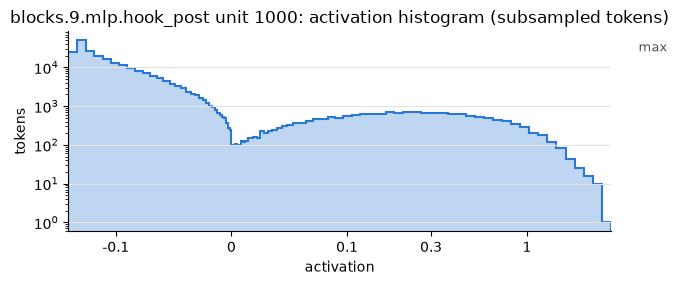

top contexts:
     3.76  an Central News Agency (KCNA) shows North Korean leader Kim Jong-Un (3«rd» R) inspecting a
     3.54  t not support him⏎⏎Kim Jong Il, far right, and son Kim Jong Un,« second» from left, salute
     3.02  Volume 2 (and omitting the events of Volume 3), the Turtles, now in« their» early thirties
     2.91  strict administration building by the 1980s. A number of people, now in« their» 50s and 60
     2.88   one-of-a«-»kind wheelchair costumes,
     2.64   will be $19.99.⏎⏎MONTHLY⏎⏎Quilt University⏎⏎Every 4th Tuesday of« each» month from 6:
     2.63  14 is still in there? Worth considering.⏎⏎Bronson Kaufusi is one of« a» trio of monster DE
     2.53  ging Vietnam war. In the midst of all this was TARIQ ALI, a young man in« his» 20s who had
     2.50   turned in.[10]⏎⏎Design details and accessories [ edit ]⏎⏎The M1918 is« a» selective-fire,
     2.49  ass of aliens into the United States would be detrimental to« the» interests of the United


In [4]:
EDGES = hists["edges"]

def show_neuron(layer, unit, n=10, hook=None, save_as=None):
    hook = hook or f"blocks.{layer}.mlp.hook_post"
    row = neurons[(neurons.hook == hook) & (neurons.unit == unit)].iloc[0]
    print(f"{hook} unit {unit}: mean {row['mean']:.3f}, std {row['std']:.3f}, max {row['max']:.2f}, "
          f"fires on {row.frac_pos:.1%} of tokens, p50 {row.p50:.3f}, p99 {row.p99:.2f}, p99.9 {row.p999:.2f}")
    counts = hists[hook][unit]
    fig, ax = plt.subplots(figsize=(7, 2.6))
    ax.stairs(counts[1:-1], EDGES, color=C[0], lw=1.5, fill=True, alpha=0.3)
    ax.stairs(counts[1:-1], EDGES, color=C[0], lw=1.5)
    ax.axvline(row["max"], color=INK2, lw=1, ls="--")
    ax.annotate("max", (row["max"], 0.9), xycoords=("data", "axes fraction"), xytext=(4, 0), textcoords="offset points", fontsize=9, color=INK2)
    nz = np.nonzero(counts[1:-1])[0]
    lo, hi = EDGES[nz[0]], EDGES[nz[-1] + 1]
    ax.set_xscale("asinh", linear_width=0.05)
    ticks = [t for t in (-1, -0.1, 0, 0.1, 0.3, 1, 3, 10, 30, 100) if lo <= t <= hi]
    ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
    ax.xaxis.set_minor_locator(plt.matplotlib.ticker.NullLocator())
    ax.set(yscale="log", xlim=(lo, hi),
           title=f"{hook} unit {unit}: activation histogram (subsampled tokens)", xlabel="activation", ylabel="tokens")
    tidy(ax)
    if save_as:
        save(fig, save_as)
    plt.show()
    for side in ("top", "bottom"):
        t = topk[(topk.hook == hook) & (topk.unit == unit) & (topk.side == side)].sort_values("rank").head(n)
        if len(t):
            print(f"{side} contexts:")
        for v, ctx in zip(t.value, t.context):
            print(f"  {v:7.2f}  {ctx[-90:]}")

show_neuron(9, 1000, save_as="results_neuron_l9_1000")

blocks.11.mlp.hook_post unit 2378: mean 1.000, std 5.352, max 58.22, fires on 5.8% of tokens, p50 -0.001, p99 37.12, p99.9 47.81


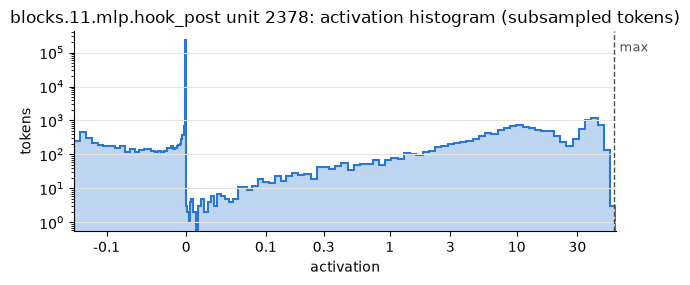

top contexts:
    58.22  ts need an operating system to operate just like our phones, tablets and laptops.«⏎»⏎"It's
    57.82  et.⏎⏎• Lents Community Garden, Southeast 88th Avenue & Steele Street.«⏎»⏎• Gilbert Heights
    57.33  Heights Road, Toronto⏎⏎Lakeshore Avenue West, Toronto⏎⏎Lisgar Street, Toronto«⏎»⏎Tipperary
    57.03  fect women's lives; just look at the decision-making tables around Scotland.«⏎»⏎"Less than
    56.91  ⏎⏎18:08:08 Alan Brown MP (Kilmarnock and Loudoun, Scottish National Party)«⏎»⏎18:21
    56.85   Cleansing or Baby Wipes after rebate⏎⏎Free CVS Pantiliners after rebate«⏎»⏎Free Wrig
    56.80  ardens Road, Toronto⏎⏎Hill Heights Road, Toronto⏎⏎Lakeshore Avenue West, Toronto«⏎»⏎Lisgar
    56.75  ybank Avenue, Toronto⏎⏎Sherway Gardens Road, Toronto⏎⏎Hill Heights Road, Toronto«⏎»⏎Lakesh
    56.66  reet.⏎⏎• Senn's Community Garden, Northeast 112th Avenue & Prescott Street.«⏎»⏎• Hazelwood
    56.66  e said, using Mr Sharon's nickname.⏎⏎"Arik loved his people, and his 

In [5]:
# The neuron with the largest peak activation in the last layer.
l11 = mlp[mlp.layer == 11].nlargest(1, "max").iloc[0]
show_neuron(11, int(l11.unit), save_as="results_neuron_l11_peak")

**A residual dimension.** Residual dimensions are signed, so the atlas keeps both extremes. Dimension 447 is the
basis dimension with the largest share of variance in layers 8–10 (§1); here it is at the input to layer 9.

blocks.9.hook_resid_pre unit 447: mean 49.346, std 12.001, max 96.94, fires on 99.9% of tokens, p50 50.269, p99 75.53, p99.9 84.60


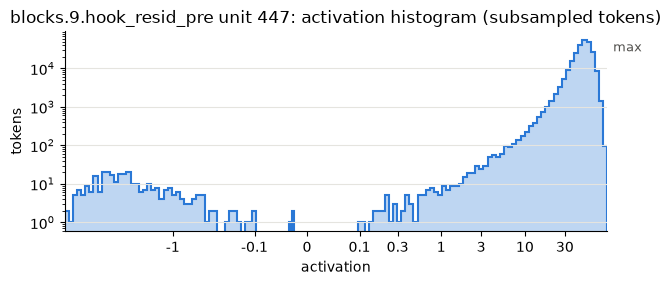

top contexts:
    96.94  ts; it makes them part of the plot.⏎⏎In fact, you could argue that« SOM»A is actually more
    96.49  Statistically, the« Canucks» have the second-
    95.56  ise well behind their upstream versions.⏎⏎In short,« Shark»Linux will automatically update
    94.30   I remember was waking up hanging from my straps in the back of my truck,”« McCl»oy said.⏎
    94.10  t session, guaranteeing integrity of the data when we go to use it in« Flask». In our case
    94.01   with reduced testosterone, and low testosterone induces weight gain,"« Sa»ad wrote in the
    94.00  yn.⏎⏎On a defense full of players that shined bright on Sunday night,« Griff»en's star out
    93.86   the most subjective. But I think we’ve achieved something special with« Ves»per, where it
    93.86  What is« Loki»P?⏎⏎
    93.82  I'm very excited to announce the« Ghostbusters» Board Game, from
bottom contexts:
   -23.44   Feb 2011 (15) Jan 2011 (20) Dec 2010 (16) Nov 2010 (14) Oct 2010 (12«)» Sep 2010

In [6]:
show_neuron(9, 447, hook="blocks.9.hook_resid_pre", save_as="results_resid_l9_447")

## 4. Statistical errors and the corpus systematic

`export` resamples the 8 shards with replacement (within each OpenWebText file) and pools them, giving a bootstrap
error on every unit's mean, std and firing rate (`*_err` columns), and on each layer's total variance and effective
dimension (§1). Whole shards are the resampling unit, so correlations between rows within a shard are accounted for.

**Corpus systematic: file 0 vs file 1.** With only 4 shards per file, each unit's error estimate is itself too noisy
for per-unit z-tests (z then follows a heavy-tailed distribution even when nothing differs). A robust test avoids
per-unit errors: compare the typical cross-file difference with the typical difference between two halves of the same
file, each in units of the unit's spread. Halves hold half the data, so their differences are divided by √2 to be
comparable. A ratio near 1 means the files differ no more than random splits do.

median bootstrap error             MLP neurons   residual dims
  on the mean, in units of std         0.0019         0.0022
  on the std, relative                 0.0047         0.0010
  on the firing rate, relative         0.0060         0.0019



|difference| / spread       cross-file   halves (÷√2)   ratio, median   ratio, 99th pct
Mean activat MLP neurons       0.0030       0.0031           0.97             0.91
Mean activat residual dims     0.0036       0.0036           1.00             0.89
Firing rate  MLP neurons       0.0031       0.0033           0.95             0.91



effective dimension by file (± bootstrap within the file)
layer  file 0           file 1           both files
    0   14.3 ± 0.0      14.3 ± 0.0      14.3 ± 0.0
    1   31.1 ± 0.0      31.2 ± 0.0      31.1 ± 0.0
    2   46.1 ± 0.1      46.3 ± 0.0      46.2 ± 0.0
    3   71.5 ± 0.1      71.9 ± 0.1      71.7 ± 0.1
    4  103.4 ± 0.3     104.1 ± 0.2     103.8 ± 0.2
    5  130.8 ± 0.4     131.8 ± 0.2     131.3 ± 0.3
    6  150.1 ± 0.6     151.3 ± 0.3     150.7 ± 0.3
    7  164.2 ± 0.6     165.2 ± 0.3     164.8 ± 0.3
    8  169.9 ± 0.5     171.0 ± 0.2     170.5 ± 0.3
    9  171.4 ± 0.5     172.2 ± 0.4     171.9 ± 0.3
   10  157.8 ± 0.6     157.7 ± 0.5     157.9 ± 0.4
   11  104.0 ± 0.6     103.8 ± 0.6     103.9 ± 0.4
   12    6.8 ± 0.1       6.8 ± 0.0       6.8 ± 0.0


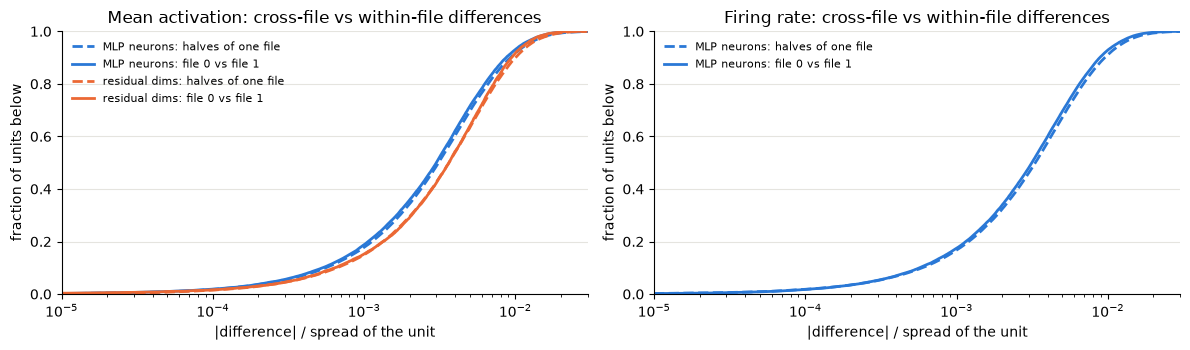

In [7]:
mlp_mask = (neurons.kind == "post").to_numpy()
print("median bootstrap error             MLP neurons   residual dims")
for label, ratio in [("on the mean, in units of std", neurons.mean_err / neurons["std"]),
                     ("on the std, relative", neurons.std_err / neurons["std"]),
                     ("on the firing rate, relative", neurons.frac_pos_err / neurons.frac_pos.where(neurons.frac_pos > 0))]:
    print(f"  {label:32s} {np.nanmedian(ratio[mlp_mask]):10.4f}   {np.nanmedian(ratio[~mlp_mask]):12.4f}")

# Per-shard moments, in the same unit order as `neurons`.
sh = pd.read_parquet(ATLAS / "shards.parquet")
S, U = sh.shard.nunique(), len(neurons)
assert (sh.hook.to_numpy()[:U] == neurons.hook.to_numpy()).all() and (sh.unit.to_numpy()[:U] == neurons.unit.to_numpy()).all()
arr = lambda col: sh[col].to_numpy().reshape(S, U)
n_s, files_s = arr("n")[:, 0], arr("file")[:, 0]
moments_s = (n_s, arr("mean"), arr("m2"), arr("n_pos"))
pool = lambda mask: pooled_moments(np.asarray(mask, float)[None], *moments_s)

f0, f1 = np.unique(files_s)
spread = {"mean": neurons["std"].to_numpy(), "frac_pos": np.sqrt(neurons.frac_pos * (1 - neurons.frac_pos)).to_numpy()}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
print("\n|difference| / spread       cross-file   halves (÷√2)   ratio, median   ratio, 99th pct")
for ax, (col, title) in zip(axes, [("mean", "Mean activation"), ("frac_pos", "Firing rate")]):
    with np.errstate(divide="ignore", invalid="ignore"):
        cross = np.abs(pool(files_s == f0)[col][0] - pool(files_s == f1)[col][0]) / spread[col]
        halves = []
        for f in (f0, f1):
            idx = np.flatnonzero(files_s == f)
            for pair in ([0, 1], [0, 2], [0, 3]):  # the three ways to split 4 shards into two halves
                h = np.zeros(S); h[idx[pair]] = 1
                halves.append(np.abs(pool(h)[col][0] - pool((files_s == f) - h)[col][0]) / spread[col] / np.sqrt(2))
    for i, (m, label) in enumerate([(mlp_mask, "MLP neurons"), (~mlp_mask, "residual dims")]):
        if col == "frac_pos" and label == "residual dims":
            continue  # "> 0" is not meaningful for residual dimensions
        c = cross[m & np.isfinite(cross)]
        h = np.concatenate([x[m & np.isfinite(x)] for x in halves])
        print(f"{title[:12]:12s} {label:13s} {np.median(c):10.4f}   {np.median(h):10.4f}   {np.median(c) / np.median(h):12.2f}   "
              f"{np.quantile(c, 0.99) / np.quantile(h, 0.99):14.2f}")
        for vals, ls, which in [(h, "--", "halves of one file"), (c, "-", f"file {f0} vs file {f1}")]:
            v = np.sort(vals)
            ax.plot(v, np.arange(1, len(v) + 1) / len(v), color=C[i], lw=2, ls=ls, label=f"{label}: {which}")
    ax.set(xscale="log", xlim=(1e-5, 3e-2), ylim=(0, 1), title=f"{title}: cross-file vs within-file differences",
           xlabel="|difference| / spread of the unit", ylabel="fraction of units below")
    ax.legend(frameon=False, fontsize=8)
    tidy(ax)
plt.tight_layout()
save(fig, "results_corpus_check")

print("\neffective dimension by file (± bootstrap within the file)")
print("layer  " + "  ".join(f"file {f:<10}" for f in resid["files"]) + "  both files")
for l in layers:
    cells = "  ".join(f"{resid['pr_file'][l, j]:5.1f} ± {resid['pr_err_file'][l, j]:<4.1f}  " for j in range(len(resid["files"])))
    print(f"{l:5d}  {cells}  {pr[l]:5.1f} ± {pr_err[l]:.1f}")

**Reading it.** Statistical errors are small: a neuron's mean is known to about 0.002 of its spread, which corresponds
to roughly 250k effective samples out of 1M tokens (tokens within documents and shards are correlated). The two
OpenWebText files differ no more than two halves of the same file (ratio about 1 in the median and the tail), and their
effective dimensions agree within about 1. That is expected: both files are random samples of the same corpus, so the
second file is a statistical replicate (different documents, same distribution), not a corpus systematic. A real corpus systematic needs a different corpus (FineWeb, code).

## 5. Regression check: pointers reproduce

Activations are a pure function of (weights, tokens), so the atlas stores exemplars as `(row, pos)` pointers. Recompute
a random sample of top- and bottom-k entries and check that each stored value comes back.

In [8]:
model = HFGPT2("cpu")
sample = topk.sample(12, random_state=0)
worst = 0.0
for r in sample.itertuples():
    got = {}
    toks = torch.tensor(tokens[[r.row]].astype(np.int64))
    model.run(toks, {r.hook: lambda act: got.__setitem__("x", act[0, r.pos, r.unit].item())})
    worst = max(worst, abs(got["x"] - r.value) / max(abs(r.value), 1e-3))
    print(f"{r.hook:26s} unit {r.unit:4d} rank {r.rank:2d}: stored {r.value:9.4f}  recomputed {got['x']:9.4f}")
print(f"worst relative difference {worst:.1e}")
assert worst < 1e-3

/Users/ryan/Development/gpt2-atlas/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 14522.67it/s]

blocks.7.mlp.hook_post     unit 1034 rank 16: stored    1.8986  recomputed    1.8986
blocks.0.mlp.hook_post     unit 3000 rank 17: stored    2.4605  recomputed    2.4605
blocks.3.hook_resid_pre    unit  342 rank 13: stored    7.0742  recomputed    7.0742
blocks.11.mlp.hook_post    unit 1657 rank 12: stored    3.2073  recomputed    3.2073


blocks.11.hook_resid_post  unit  640 rank  6: stored   45.2532  recomputed   45.2532
blocks.3.mlp.hook_post     unit  350 rank  6: stored    1.8424  recomputed    1.8424
blocks.8.hook_resid_pre    unit  157 rank 11: stored  -11.6574  recomputed  -11.6574
blocks.6.hook_resid_pre    unit  517 rank 14: stored    8.6394  recomputed    8.6394
blocks.0.mlp.hook_post     unit  825 rank  3: stored    2.5382  recomputed    2.5382


blocks.1.mlp.hook_post     unit 2564 rank  2: stored    2.0901  recomputed    2.0901
blocks.7.mlp.hook_post     unit 3001 rank 16: stored    3.0929  recomputed    3.0929
blocks.11.mlp.hook_post    unit 2843 rank 10: stored    3.3859  recomputed    3.3859
worst relative difference 9.2e-07
